# Exercise 5 — Interactive AI Prototyping with Gradio

**Author:** Mayank Mishra  
**Date:** 21 November 2026  
**Environment:** Python 3.12, Gradio

## Objective

Build an interactive chatbot with Gradio's `gr.ChatInterface`, add a title,
welcome text, and sample prompts, launch it locally, and capture a screenshot
of the working interface.

The chatbot in this exercise is deliberately **rule-based**. It does not call an
external language-model API, so it runs without an API key. The same interface
can later be connected to a hosted LLM.

## 1. Import Gradio and helper libraries

In [1]:
import re
import time
from pathlib import Path

import gradio as gr
import requests

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "Exercise5"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Gradio version: {gr.__version__}")
print(f"Output folder : {OUTPUT_DIR}")

Gradio version: 6.32.0
Output folder : C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise5


## 2. Define the chatbot response function

In [2]:
def chatbot(message, history):
    """Return a rule-based reply for the supplied user message."""
    text = (message or "").lower().strip()

    if not text:
        return "Please type a question so I can help."

    if re.search(r"\b(hello|hi|hey|greetings)\b", text):
        return "Hello! Welcome to my AI chatbot. How can I help you today?"

    if "how are you" in text:
        return "I am doing well, thank you! What would you like to explore?"

    if "machine learning" in text or " ml " in f" {text} ":
        return (
            "Machine learning is a branch of AI in which models learn patterns "
            "from data and use them to make predictions or decisions."
        )

    if "python" in text:
        return (
            "Python is a popular, readable programming language used for data "
            "science, automation, web development, and AI."
        )

    if "gradio" in text:
        return (
            "Gradio is a Python library for quickly building interactive web "
            "interfaces for machine-learning models and data applications."
        )

    if "data science" in text or "pandas" in text:
        return (
            "Data science combines statistics, programming, and domain knowledge "
            "to turn data into useful insights. pandas is a key Python library "
            "for tabular data analysis."
        )

    if re.search(r"\b(bye|goodbye|thanks|thank you)\b", text):
        return "You're welcome! Thanks for trying the demo chatbot."

    return (
        "Thank you for your question! I am a demonstration chatbot. "
        "Try asking about Python, machine learning, Gradio, or data science."
    )

## 3. Create the ChatInterface with title, welcome text, and examples

In [3]:
demo = gr.ChatInterface(
    fn=chatbot,
    title="My AI Chatbot",
    description=(
        "Welcome! Ask questions about Python, machine learning, Gradio, "
        "and general topics. This demo runs locally without an API key."
    ),
    examples=[
        "Hello!",
        "What is Python?",
        "Explain machine learning.",
        "What is Gradio?",
    ],
    cache_examples=False,
)

## 4. Launch the interface and verify that it responds

In [4]:
PORT = 7860

app, local_url, share_url = demo.launch(
    server_name="127.0.0.1",
    server_port=PORT,
    prevent_thread_lock=True,
    show_error=True,
    quiet=True,
    footer_links=[],
    theme=gr.themes.Soft(primary_hue="teal", neutral_hue="slate"),
    css="""
    .gradio-container {max-width: 1100px !important; margin: auto !important;}
    footer {display: none !important;}
    """,
)

time.sleep(2)
try:
    response = requests.get(local_url, timeout=15)
    print(f"Local URL   : {local_url}")
    print(f"HTTP status : {response.status_code}")
    print("Interface launched successfully." if response.ok else "Interface error.")
finally:
    demo.close()
    print("Demo server closed after verification.")

Local URL   : http://127.0.0.1:7860/
HTTP status : 200
Interface launched successfully.
Closing server running on port: 7860
Demo server closed after verification.


## 5. Screenshot of the running interface

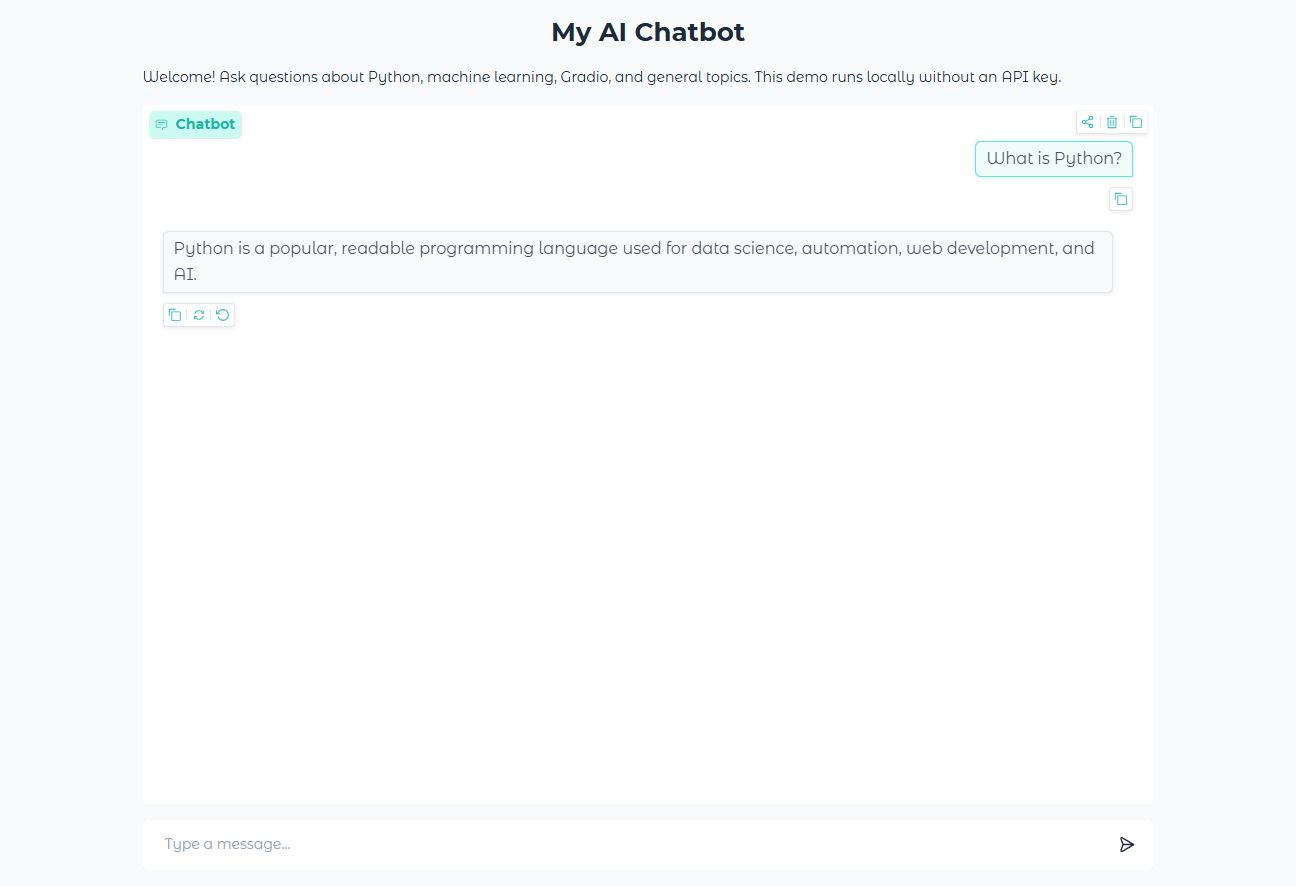

Loaded screenshot: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise5\gradio_screenshot.png


In [5]:
from IPython.display import Image, display

screenshot_path = OUTPUT_DIR / "gradio_screenshot.png"

if screenshot_path.exists():
    display(Image(filename=str(screenshot_path)))
    print(f"Loaded screenshot: {screenshot_path}")
else:
    print(
        "Screenshot not found yet. Launch Exercise5_app.py, capture the "
        "browser window, and save it as outputs/Exercise5/gradio_screenshot.png."
    )

## Conclusion

- A working Gradio chatbot was created with `gr.ChatInterface`.
- The interface includes a title, a welcome message, and four sample prompts.
- The app was launched locally on `127.0.0.1:7860`, checked with an HTTP
  request, and then closed cleanly.
- The chatbot is rule-based and requires no API key. It can be upgraded to a
  generative model by replacing the `chatbot()` function with a call to an LLM
  API while keeping the same Gradio interface.
- The screenshot in `outputs/Exercise5/gradio_screenshot.png` documents the
  working interface. The reusable standalone source is `Exercise5_app.py`.

**Deliverables produced:** notebook, `Exercise5_app.py`, and
`gradio_screenshot.png`.